<img src='./img/up_bann.png' style="display: block; margin: 0 auto;">

*These algorithms come from an **ESA R&D project** and are validated* 

# Parcel Delineation with Sentinel-2 🌾 🥔 🌽 🛰️

## Challenge #2 @ 12th CASSINI  Hackathon: Space-enabled crisis response and civil resilience


Can we detect Crop Fields with the [APEx Algorithms](https://algorithm-catalogue.apex.esa.int/)?

This notebook runs the [Parcel Delineation based on ML using Sentinel-2 algorithm](https://algorithm-catalogue.apex.esa.int/apps/parcel_delineation) over the upstream area of the Kakhovka Dam near Bratoliubivka village, in the Kherson Oblast. The field boundaries first appeared in the [BSI notebook](./apex_bsi.ipynb).<br>

If you are new to APEx, start with [APEx 101](./apex_101.ipynb).

By the end of this notebook, you will be able to...

- Run the Parcel Delineation algorithm from the APEx Catalogue
- Open the result as a GeoTIFF and visualise the detected fields and check the result against an optical image and state its limits
- Estimate the total and average area of detected fields


### **Prerequisites:**

#### 🛠️ Dependencies 
As we will be working with the APEx algorithms, you will need a free [free CDSE account](https://dataspace.copernicus.eu/ecosystem/join)  for the openEO jobs. Install the following alongside your EO tools:

```text
- git
- git+https://github.com/ESA-APEx/apex_algorithms.git # The up-to-date version of apex_algorithms
- openeo
```
You can make use of the `environment.yml` available in this repository to run all the notebooks!

#### 🛰️ openEO 

As the algorithms run in openEO, it is good to have an understanding of [openEO UDPs](https://open-eo.github.io/openeo-python-client/udp.html). You can find examples that explain how to use the `openeo` library in their [Python Client Examples](https://github.com/Open-EO/openeo-community-examples/tree/main/python).

#### 🔐 Github Authentication 
The `esa_apex_toolbox` library reads the catalogue from the remote GitHub repository, not from local changes.
You can find more informaiton on how to get your token [here](https://esa-apex.github.io/apex_algorithms/toolbox.html#github-authentication).

If your environment defines `GITHUB_TOKEN`, the token cell below picks it up. Otherwise you will be asked for one, and you can press Enter to continue without it.

With the packages installed, we can start. 🚀 🛰️

### Import the libraries

These libraries cover the APEx toolbox, the openEO connection, the STAC catalogue, raster and vector data, and the maps.

In [1]:
import io
from getpass import getpass
import os

from esa_apex_toolbox.algorithms import GithubAlgorithmRepository
import openeo
import rioxarray
import rasterio
import numpy as np
import geopandas as gpd

from pystac_client import Client

from shapely.geometry import box
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import folium
from IPython.display import display, HTML

### Customised functions

This function shows the detected fields on an interactive map. If the layer's EPSG code differs from the basemap's (EPSG:4326), it reprojects the layer first.

In [2]:
def visualising_fields(field_xarray):
    """Show a one-band field raster on an interactive map."""
    
    da_4326 = field_xarray.rio.reproject("EPSG:4326", resampling=0)  # 0 = nearest neighbor

    # we keep the values larger than 0 as detected parcels
    is_one = (da_4326 >= 0).values

    # we build a transparent RGBA image (H, W, 4)
    rgba = np.zeros((*is_one.shape, 4), dtype=np.float32)
    rgba[is_one] = [0, 0, 0, 220]

    # we add to our basemap
    west, south, east, north = da_4326.rio.bounds()
    m = folium.Map(location=[(south + north) / 2, (west + east) / 2], zoom_start=12)

    folium.raster_layers.ImageOverlay(
        image=rgba,
        bounds=[[south, west], [north, east]],
        name="Detected Mask (1s)",
        interactive=True
    ).add_to(m)

    folium.LayerControl().add_to(m)
    
    return display(HTML(m._repr_html_()))

### GitHub token

We read the GitHub token from your environment. If none is set, you will be asked for one. Press Enter to continue without it.

In [3]:
github_token = os.environ.get('GITHUB_TOKEN') or os.environ.get('GH_TOKEN')
if not github_token:
    github_token = getpass('GitHub token (optional; Enter for unauthenticated access): ') or None

> ##### Remember
> Always **treat a token as a password**: never print it, put it in a committed file, or include it in notebook outputs. Revoke and replace it immediately if exposed; replace it when it expires. The token is used only for GitHub API requests that list the catalogue folder. Downloads of catalogue and process files do not use it.

## 1️⃣ Accessing the algorithms

We access APEx Catalogue metadata on GitHub and look up the algorithm by its id.

In [4]:
repo = GithubAlgorithmRepository(
    owner='ESA-APEx',
    repo='apex_algorithms',
    folder='algorithm_catalog',
    branch='main',
    token=github_token,
)

We are interested in the **Parcel Delineation based on ML using Sentinel-2** (`parcel_delineation`):<br>

The catalogue describes parcel delineation as the identification and marking of agricultural boundaries. Accurate delineation also aids in classifying crop types and managing farmland more effectively.

We look up each algorithm by its `id`. You can find each `id` on the algorithm's page in the [APEx Catalogue](https://algorithm-catalogue.apex.esa.int/).


In [5]:
pd_algorithm = repo.get_algorithm('parcel_delineation')
pd_algorithm

Algorithm(id='parcel_delineation', title='Parcel Delineation based on ML using Sentinel-2', description='An openEO process example for delineating agricultural parcels based on ML using Sentinel-2 data.', udp_link=UdpLink(href='https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/main/algorithm_catalog/vito/parcel_delineation/openeo_udp/parcel_delineation.json', title='openEO Process Definition'), service_links=[ServiceLink(href='https://openeofed.dataspace.copernicus.eu', title='CDSE openEO federation')], license=None, organization='VITO', provider='VITO', platforms=['CDSE'], keywords=['Agriculture', 'Sentinel-2'])

Printing the algorithm shows its **title**, **id**, and **related metadata**. We are interested in the `udp_link` parameter, as it will give us access to the **UDP** we need.
<br>

Each algorithm’s `udp_link` points to the corresponding openEO process within the APEx Catalogue. We take its `href` (the web address), and use it to build our job.

In [6]:
pd_link = pd_algorithm.udp_link.href
pd_link

'https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/main/algorithm_catalog/vito/parcel_delineation/openeo_udp/parcel_delineation.json'

## 2️⃣ Defining the area and time frame of interest: Bratoliubivka Fields

In the [BSI notebook](./apex_bsi.ipynb), the time series showed agricultural fields in the Kherson Oblast. We focus on the area north of Bratoliubivka village.

We define a bounding box. The box covers about 6,000 ha. The code below computes the exact area.

In [7]:
geometry = [33.802872,46.860895,33.927155,46.917910]  # west, south, east, north
shape = {'west': geometry[0], 'south': geometry[1], 'east': geometry[2], 'north': geometry[3]}

# we show the area of interest on a map
aoi = gpd.GeoSeries(box(*geometry), crs='EPSG:4326')
aoi.explore(color='red')

In [8]:
# area of the bounding box in hectares (UTM zone 36N, EPSG:32636)
print(f"Bounding box area: {aoi.to_crs('EPSG:32636').area.iloc[0] / 10_000:,.0f} ha")

Bounding box area: 5,999 ha


The [BBC reports](https://www.bbc.com/news/world-europe-65818705) that the Kakhovka Dam collapsed on 6 June 2023. This notebook runs the detection for the period after that date. The catalogue lists that the algorithm keeps scenes with at most 10% cloud cover and applies a cloud mask based on the SCL layer.<br>

To understand how many images will be processed we can filter the  metadata for the Sentinel-2 L2A collection. We search the [CDSE STAC API](https://browser.stac.dataspace.copernicus.eu/) Catalogue for Sentinel-2 L2A images from June and July 2023 with 10% or less cloud cover, the same limit the algorithm applies.

In [9]:
# we define our filter parameters 
max_cloud_cover = 10
start_end_date = ["2023-06-01","2023-07-31"]

# we connect to Copernicus Data Space STAC catalog
stac_url = "https://catalogue.dataspace.copernicus.eu/stac"
client = Client.open(stac_url)

# filter metadata based on the cloud cover filter
search = client.search(
        collections=["sentinel-2-l2a"],
        bbox=geometry,
        datetime= start_end_date,
        query={"eo:cloud_cover": {"lte": max_cloud_cover}},
        sortby=[{"field": "properties.datetime", "direction": "asc"}],
        limit=60,)

items = search.item_collection()
print(f"{len(items)} images match the search")

13 images match the search


We will see that we get 13 images that match the cloud percentage we are looking for over period of interest. The job works from these images over the two months.

In [10]:
for item in search.item_collection():
    print(f"  {item.datetime.date()}  {item.properties['eo:cloud_cover']:.1f}% cloud")

  2023-06-03  2.8% cloud
  2023-06-03  3.6% cloud
  2023-06-05  0.2% cloud
  2023-06-05  0.0% cloud
  2023-06-18  3.5% cloud
  2023-06-20  0.1% cloud
  2023-06-20  4.0% cloud
  2023-06-30  1.1% cloud
  2023-06-30  2.9% cloud
  2023-07-03  8.6% cloud
  2023-07-05  0.4% cloud
  2023-07-05  5.0% cloud
  2023-07-30  6.8% cloud


## 3️⃣ Running the algorithm in the CDSE openEO federation

We will run our **job** through the CDSE openEO federation. Our workflow consist on:

1. Connect to the backend.
2. Build the process, run the job and access the result.
3. Acces the results with the help of `rasterio` and `rioxarray`

The first step is connecting to the CDSE openEO federation backend. The first time you run this cell, a browser window opens for you to log in.

In [11]:
connection = openeo.connect("openeofed.dataspace.copernicus.eu").authenticate_oidc() # connecting

Authenticated using refresh token.


Once connected, we define the first job. 

To build this job, we pass the algorithm's `process_id`, its location in the catalogue (`namespace`), the date range (`temporal_extent`) and the area of interest (`spatial_extent`). [APEx 101](./apex_101.ipynb) explains how user-defined processes work

In [12]:
parcel_del = connection.datacube_from_process(
    process_id= pd_algorithm.id,      # id
    namespace = pd_link,              # retrieved udp_link
    temporal_extent = start_end_date, # defined date_range
    spatial_extent = shape            # our aoi
)

Creating the job sends its definition to the CDSE backend. It does not run the job yet.

In [13]:
# we create and launch our job
job = parcel_del.create_job(
        title=f'Parcel Delineation for the {start_end_date[0]} to {start_end_date[1]}',
        out_format="GTiff")
job

<BatchJob job_id='cdse-j-2611261437034590b7b284f7a0028dbe'>

With the `start_and_wait` function, we will be able to visualise the progress of our job in the CDSE openEO backend.

In [14]:
job.start_and_wait() # with this line we run our job and visualise the results dashboard

0:00:00 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': send 'start'
0:00:02 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': queued (progress 0%)
0:00:08 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': queued (progress 0%)
0:00:15 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': queued (progress 0%)
0:00:22 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': queued (progress 0%)
0:00:32 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': queued (progress 0%)
0:00:45 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': queued (progress 0%)
0:01:01 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': queued (progress 0%)
0:01:20 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': running (progress N/A)
0:01:44 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': running (progress N/A)
0:02:14 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': running (progress N/A)
0:02:52 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': running (progress N/A)
0:03:39 Job 'cdse-j-2611261437034590b7b284f7a0028dbe': running (progress N/A)
0:04:37 Jo

<BatchJob job_id='cdse-j-2611261437034590b7b284f7a0028dbe'>

During test runs, the job took about 8 minutes. Your time will depend on the queue and your connection.<br>

When the job finishes, we load its result. `get_results` allows us to access the job's output files, and `get_assets` lists them. The catalogue lists the output as a **GeoTIFF** raster that carries its map coordinates. We will access the file and open it with `rioxarray`.

In [15]:
results = job.get_results()
# find the GeoTIFF among the job's output files
tiff_asset = next(a for a in results.get_assets() if a.key.endswith(".tif"))
asset_url = tiff_asset.href

# we get the Bearer authentication headers from openEO connection
response = connection.session.get(asset_url)
response .raise_for_status()


# stream our netcdf directly into xarray
pd_result = rioxarray.open_rasterio(io.BytesIO(response.content))

pd_result

<xarray.DataArray (band: 1, y: 645, x: 955)> Size: 5MB
[615975 values with dtype=float64]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 5kB 5.196e+06 5.196e+06 ... 5.19e+06 5.19e+06
  * x            (x) float64 8kB 5.611e+05 5.611e+05 ... 5.707e+05 5.707e+05
    spatial_ref  int64 8B 0
Attributes:
    institution:          Copernicus Data Space Ecosystem openEO API - 0.74.0...
    PROCESSING_SOFTWARE:  0.74.0a15
    AREA_OR_POINT:        Area
    _FillValue:           nan
    scale_factor:         1.0
    add_offset:           0.0

> ##### Remember
> Run times depend on your connection, the backend and the queue. [APEx](https://apex.esa.int/) prepares the algorithm's process in the background. You submit only the parameters you choose, and retrieve the result 🌍✅


The result consists of one band. Each pixel holds a feature ID, so pixels of the same field share one value.

In [16]:
print(f"Bands: {pd_result.shape[0]}")

Bands: 1


## 4️⃣ Visualising the detected fields

We can visualise our resulting fields in an interactive map with help of our predefined function `visualising_fields`.

Before you read through... Estimate how many fields this area contains and their average size. Note your numbers, then check them against the results.


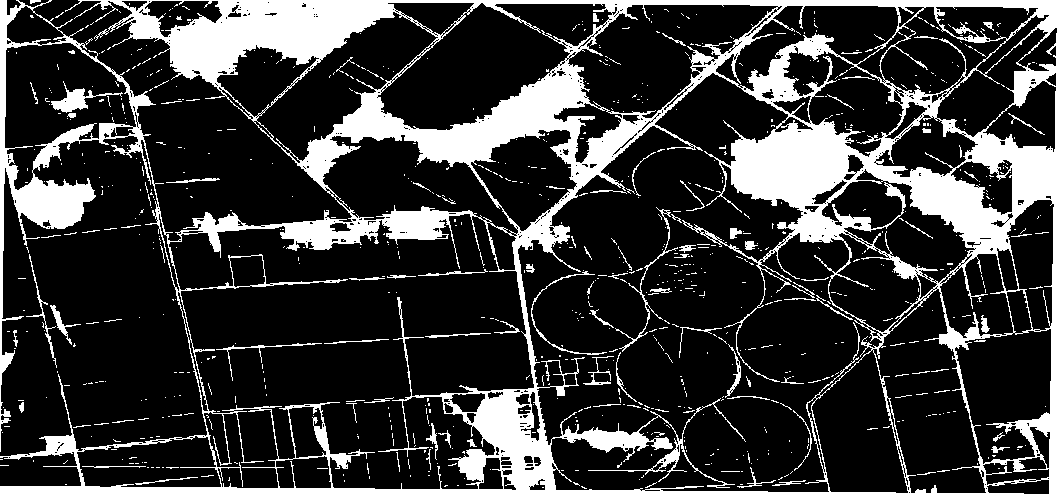

In [17]:
# Call your existing functions directly
m = visualising_fields(pd_result[0])
m

**How to read the maps**: 

- Black areas are pixels detected as fields.
- Patches may be settlements, such as Bratoliubivka village, or artefacts from the cloud mask. The optical check below helps tell them apart.

### 👓 Optical check: true-colour image

Optical images give a second view of the same area. They need cloud-free skies, so their usefulness varies by date.

We viewed a true-colour image from 20 June 2023 in the [CDSE Browser](https://browser.dataspace.copernicus.eu/). To find an image for your own date, search the same catalogue and open its true-colour preview.

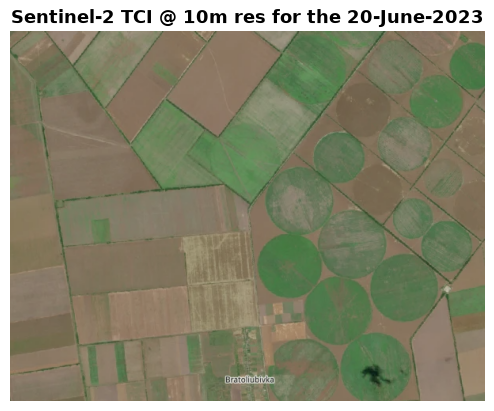

In [18]:
img_farm = mpimg.imread("./img/parcels_20_06_23.png")

#  visualise tci
plt.imshow(img_farm)
plt.title("Sentinel-2 TCI @ 10m res for the 20-June-2023", fontsize=13, fontweight="bold")
plt.axis("off")
plt.show()

## 5️⃣ Measuring the detected area

We calculate the detected area and the average field area in four steps:

- Open our GeoTIFF
- Read its pixel size from the metadata.
- Count detected fields and how many pixels belong to each feature
- Convert the count to hectares:

$$
\text{Detected area (ha)} = \frac{\text{detected pixels} \times \text{pixel area (m}^2\text{)}}{10{,}000}
$$

where the pixel area is the square of the pixel size in metres:

$$
\text{pixel area (m}^2\text{)} = \text{resolution x (m)} \times \text{resolution y (m)}
$$

In [19]:
# we access the metadata:
pd_tiff = rasterio.open(io.BytesIO(response.content))
resolution = pd_tiff.res

# we exclude the pixels that are not fields:
valid_values = pd_result.values[~np.isnan(pd_result.values)]

# We ge tthe number of detected fields 
values, counts = np.unique(valid_values, return_counts=True)


# We compute the average count per detected fields
avg_count = counts.mean()

# we calculate the total hecates:
n_field_pixels = int(len(valid_values))
total_detected_area = (n_field_pixels * (resolution[0]*resolution[1]) )/ 10000

average_field_area = (avg_count * (resolution[0]*resolution[1]) )/ 10000


print(f"Total Detected Features: {len(values)}")
print(f"Resolution:      {resolution[0]:.0f} m x {resolution[1]:.0f}")
print(f"The total detected area is {total_detected_area:,.2f} ha")   
print(f"The average field area is {average_field_area:.2f} ha")  

Total Detected Features: 696
Resolution:      10 m x 10
The total detected area is 4,943.21 ha
The average field area is 7.10 ha


**Questions to answer**
- What is the total field detected area? In the test run, the detected area was **4,943.21 ha** out of the **6,000** ha enclosed in our bounding box.
- What is the average field size? Our average size is 7.10 ha

**Limits**
The areas cover only the bounding box defined above. The result has no accuracy check, so the areas are detected, not verified. A next step is to compare the detected fields with surveyed field boundaries.

## 6️⃣ Takeaways



In this notebook you ran the [Parcel Delineation](https://algorithm-catalogue.apex.esa.int/apps/parcel_delineation#preview-information) algorithm once over the Bratoliubivka area for June and July 2023, retrieved the result, and measured the detected area.

The job ran the whole pipeline in a single run. This means you: **computed NDVI**, **predicted delineation** with the **U-Net model** and **optimised and labeld** with a **Sobel filter** by only providing an **interest period** and a **bounding box**!

You can reuse this workflow for any place or event:

1. **Run the algorithm once:** Submit your area and dates. The job runs the full pipeline.
2. **Visualise and check:** Compare the map with an optical image, and note where the boundaries match and where they do not.
3. **Measure:** Compute the detected area and the average field area.

The result covers only the bounding box you define, and it has no accuracy check against surveyed boundaries. You can test it further with validated datasets!

To use another area or event, change the area and the dates. The steps stay the same. Check each algorithm's inputs first, because other algorithms take different parameters.

## Ready for the next application?

[APEx](https://apex.esa.int/) gives you a catalogue of ESA-validated Earth observation algorithms process directly Sentinel data.<br>

Choose an algorithm, define your area and dates, and the cloud platform returns a result you can map and analyse. @ the [12th CASSINI Hackathon](https://www.cassini.eu/hackathons/), you decide what to recognise and what to act on.

<img src='./img/low_bann.png' style="display: block; margin: 0 auto;">